In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
DATA = Path('ROUND_4')
DAYS = [1, 2, 3]

prices_frames, trades_frames = [], []
for d in DAYS:
    p = pd.read_csv(DATA / f'prices_round_4_day_{d}.csv', sep=';')
    p['abs_ts'] = (d - 1) * 1_000_000 + p['timestamp']
    p['day'] = d
    prices_frames.append(p)
    t = pd.read_csv(DATA / f'trades_round_4_day_{d}.csv', sep=';')
    t['abs_ts'] = (d - 1) * 1_000_000 + t['timestamp']
    t['day'] = d
    trades_frames.append(t)

prices = pd.concat(prices_frames, ignore_index=True)
trades = pd.concat(trades_frames, ignore_index=True)

PRODUCTS = sorted(prices['product'].unique())
BOTS     = sorted(set(trades['buyer'].unique()) | set(trades['seller'].unique()))
MAX_TS   = prices['abs_ts'].max()

BOT_COLORS   = plt.cm.tab10.colors
bot_color    = {b: BOT_COLORS[i % 10] for i, b in enumerate(BOTS)}
day_bounds   = [(d - 1) * 1_000_000 for d in DAYS[1:]]

def make_xticks(step=200_000):
    pos = list(range(0, int(MAX_TS) + 1, step))
    lbl = [f'd{p // 1_000_000 + 1}\n{(p % 1_000_000)//1000}k' for p in pos]
    return pos, lbl

XT_POS, XT_LBL = make_xticks()

def day_vlines(ax):
    for xb in day_bounds:
        ax.axvline(xb, color='grey', lw=0.6, ls=':')

print('Bots   :', BOTS)
print('Products:', PRODUCTS)

Bots   : ['Mark 01', 'Mark 14', 'Mark 22', 'Mark 38', 'Mark 49', 'Mark 55', 'Mark 67']
Products: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']


## Bot names and volume per day

Bot volume (combined buy + sell) per day:

         day1  day2  day3  total
bot                             
Mark 14  3012  2736  2970   8718
Mark 01  2261  2414  2753   7428
Mark 55  2109  2289  2153   6551
Mark 22  1806  1804  2279   5889
Mark 38  1823  1500  1677   5000
Mark 67   519   567   424   1510
Mark 49   380   440   366   1186


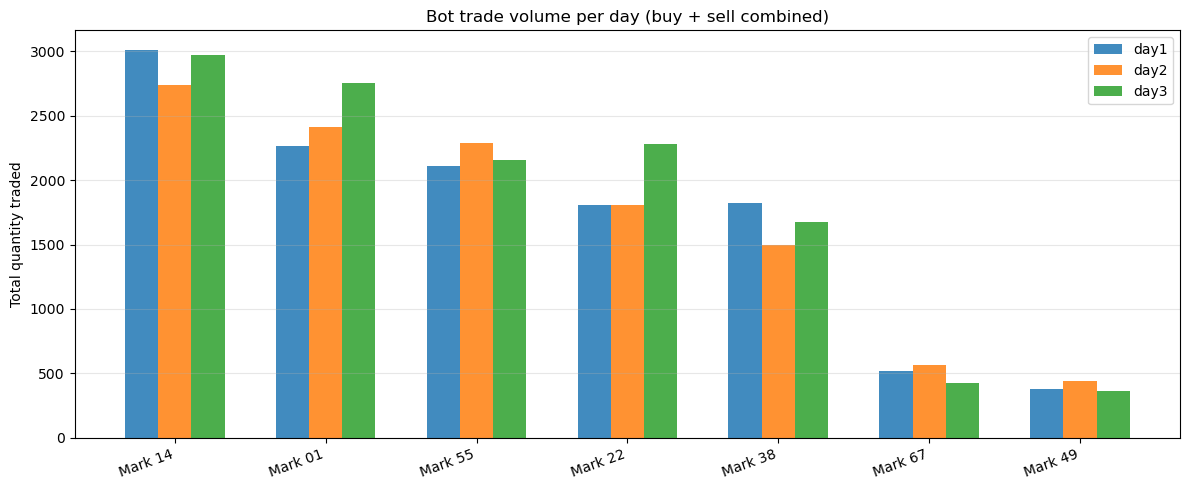

In [2]:
# ── Volume table ──────────────────────────────────────────────────────────────
buy_side  = trades[['day','buyer','symbol','quantity']].rename(columns={'buyer':'bot'})
sell_side = trades[['day','seller','symbol','quantity']].rename(columns={'seller':'bot'})
all_sides = pd.concat([buy_side, sell_side])

vol_table = (all_sides.groupby(['bot','day'])['quantity']
             .sum().reset_index()
             .pivot(index='bot', columns='day', values='quantity')
             .fillna(0).astype(int))
vol_table.columns = [f'day{c}' for c in vol_table.columns]
vol_table['total'] = vol_table.sum(axis=1)
vol_table = vol_table.sort_values('total', ascending=False)

print('Bot volume (combined buy + sell) per day:\n')
print(vol_table.to_string())

# ── Bar chart ─────────────────────────────────────────────────────────────────
day_cols = [c for c in vol_table.columns if c.startswith('day')]
x = np.arange(len(vol_table))
w = 0.22
fig, ax = plt.subplots(figsize=(12, 5))
for i, dc in enumerate(day_cols):
    ax.bar(x + i * w, vol_table[dc], width=w, label=dc, alpha=0.85)
ax.set_xticks(x + w)
ax.set_xticklabels(vol_table.index, rotation=20, ha='right')
ax.set_ylabel('Total quantity traded')
ax.set_title('Bot trade volume per day (buy + sell combined)')
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## PnL graphs for each bot
Mark-to-market PnL = cumulative cash flows from trades + current_position × current_mid_price.
Starts at 0 (no positions). Options theta decay will show as PnL drift for option-heavy bots.

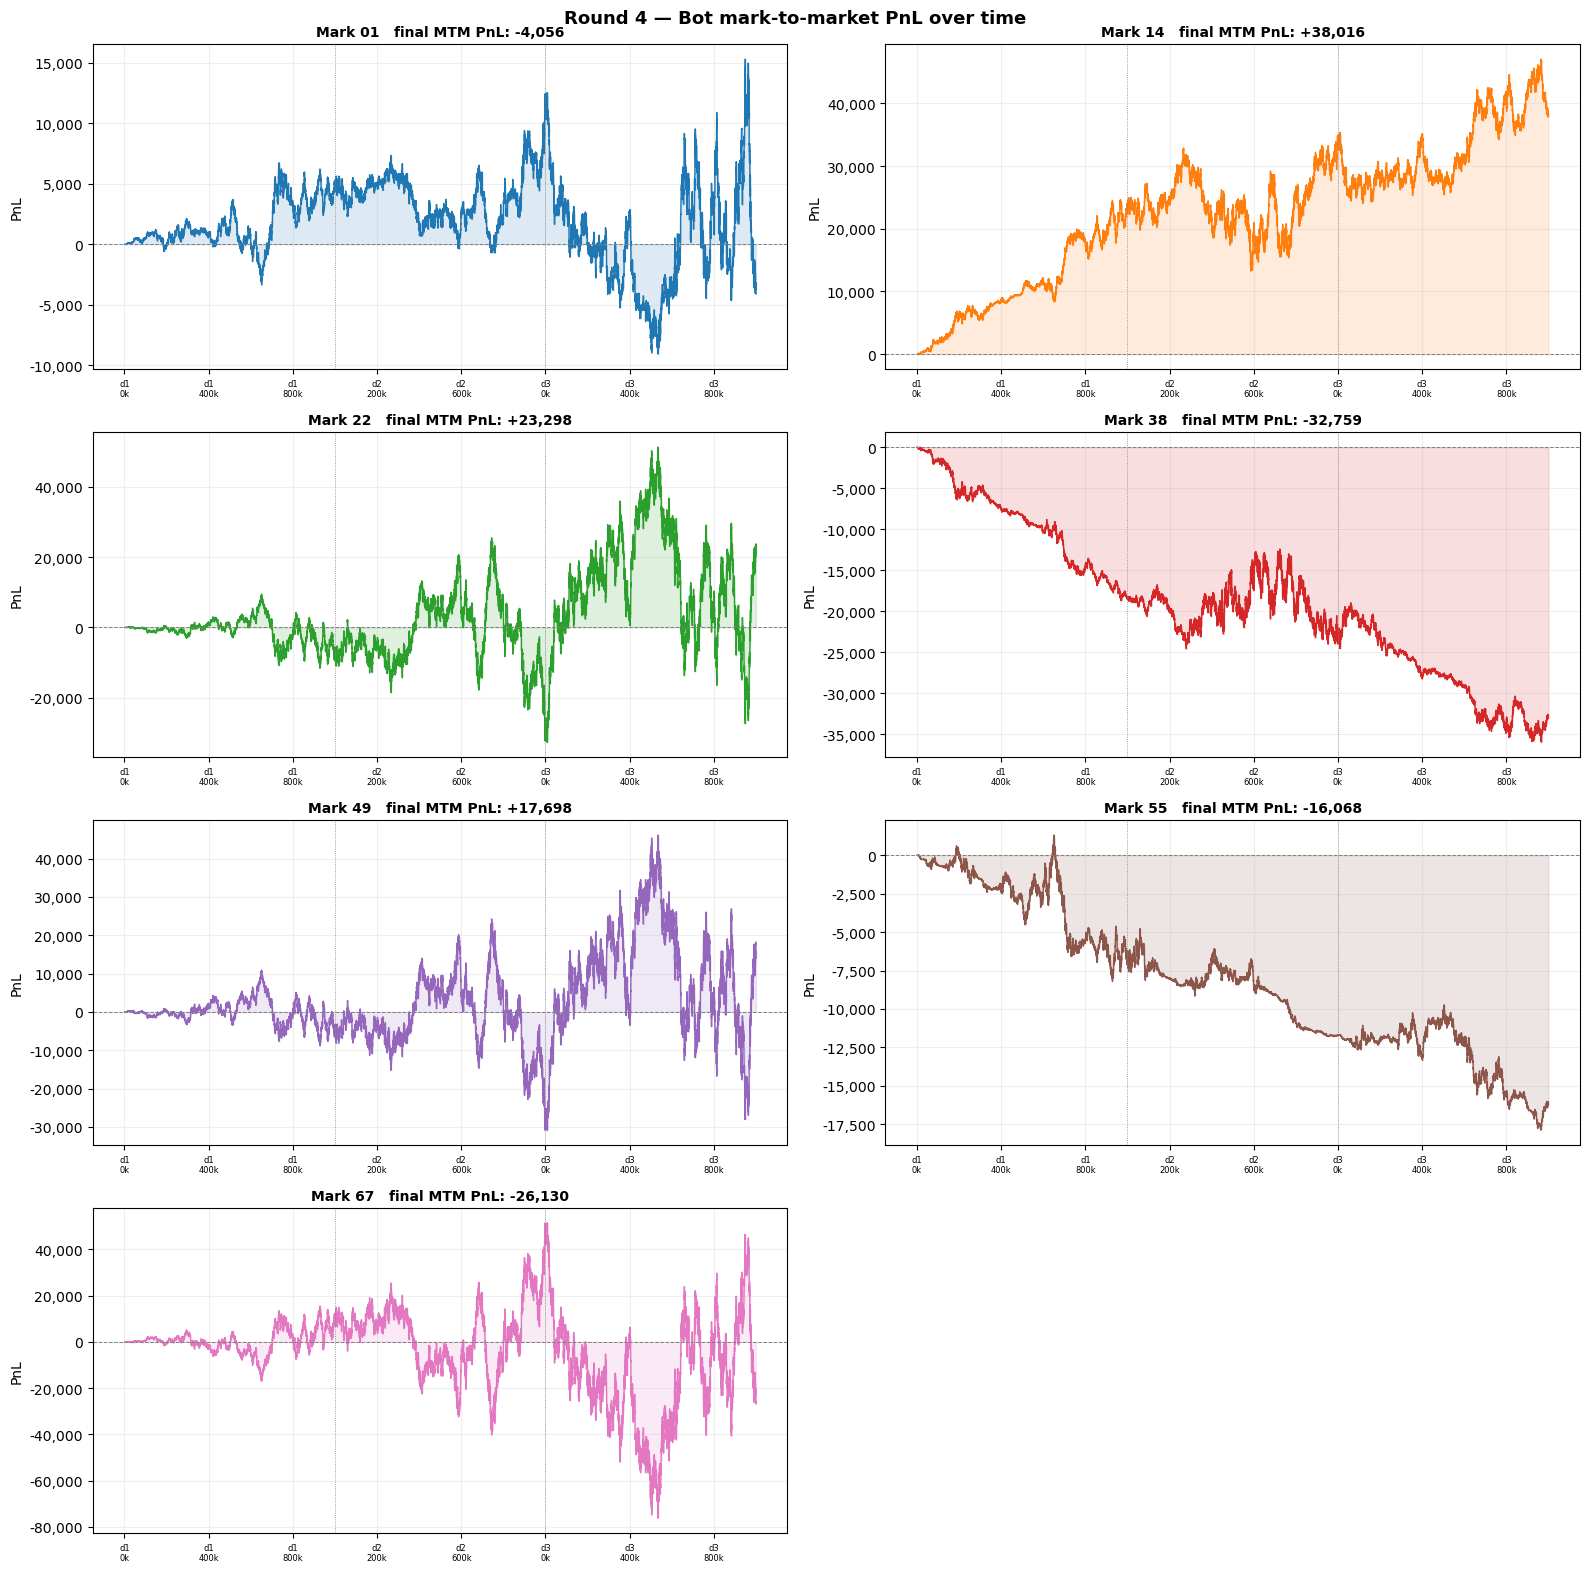

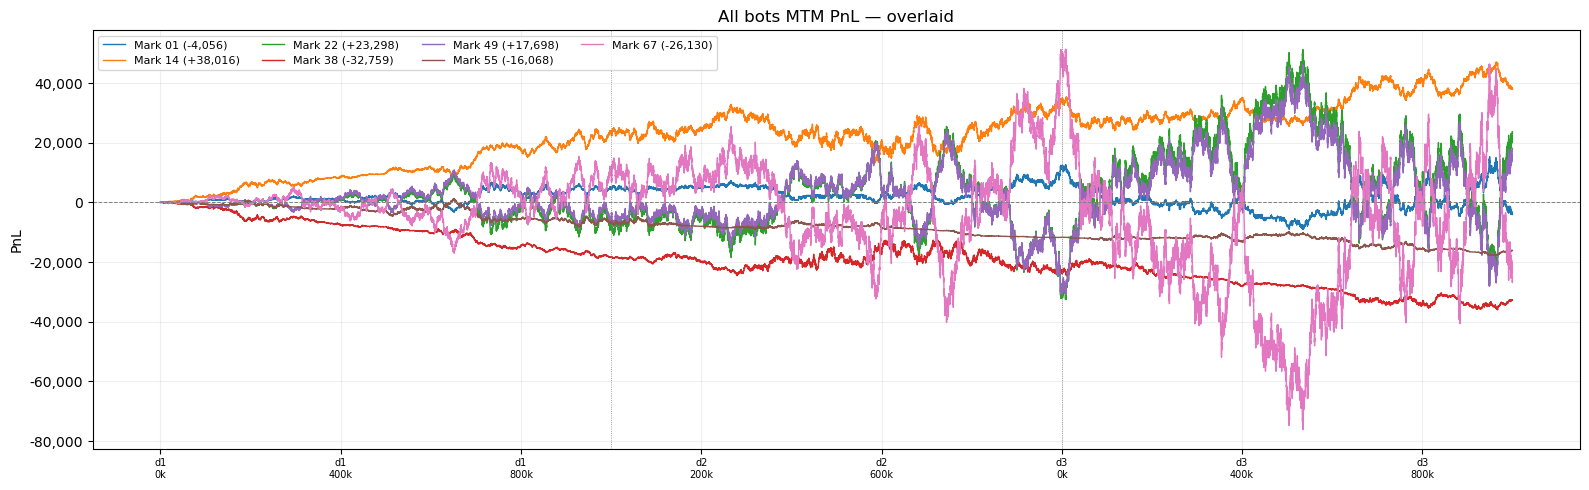

In [3]:
price_snap = prices[['abs_ts','product','mid_price']].copy()

def bot_pnl_series(bot):
    """Returns a Series of cumulative MTM PnL indexed by abs_ts."""
    bt = trades[(trades['buyer'] == bot) | (trades['seller'] == bot)].copy()
    bt['signed_qty']  = bt.apply(lambda r:  r['quantity'] if r['buyer'] == bot else -r['quantity'], axis=1)
    bt['cash_flow']   = bt.apply(lambda r: -r['price'] * r['quantity'] if r['buyer'] == bot
                                  else r['price'] * r['quantity'], axis=1)
    products = bt['symbol'].unique()
    parts = []
    for prod in products:
        pt = bt[bt['symbol'] == prod].sort_values('abs_ts').copy()
        pt['cum_qty']  = pt['signed_qty'].cumsum()
        pt['cum_cash'] = pt['cash_flow'].cumsum()
        pp = price_snap[price_snap['product'] == prod].sort_values('abs_ts')
        merged = pd.merge_asof(pp, pt[['abs_ts','cum_qty','cum_cash']], on='abs_ts', direction='backward')
        merged[['cum_qty','cum_cash']] = merged[['cum_qty','cum_cash']].fillna(0)
        merged['mtm'] = merged['cum_cash'] + merged['cum_qty'] * merged['mid_price']
        parts.append(merged.set_index('abs_ts')['mtm'])
    if not parts:
        return pd.Series(dtype=float)
    combined = pd.concat(parts, axis=1)
    combined = combined.ffill().fillna(0)
    return combined.sum(axis=1)

# compute once
pnl_all = {bot: bot_pnl_series(bot) for bot in BOTS}

# ── One subplot per bot ───────────────────────────────────────────────────────
ncols = 2
nrows = (len(BOTS) + 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows), squeeze=False)
axes_flat = axes.flatten()

for i, bot in enumerate(BOTS):
    ax = axes_flat[i]
    s = pnl_all[bot]
    if s.empty:
        ax.set_visible(False)
        continue
    color = bot_color[bot]
    ax.plot(s.index, s.values, color=color, lw=1.0)
    ax.fill_between(s.index, s.values, alpha=0.15, color=color)
    ax.axhline(0, color='grey', lw=0.7, ls='--')
    day_vlines(ax)
    final = s.iloc[-1]
    ax.set_title(f'{bot}   final MTM PnL: {final:+,.0f}', fontsize=10, fontweight='bold')
    ax.set_ylabel('PnL')
    ax.set_xticks(XT_POS[::2]); ax.set_xticklabels(XT_LBL[::2], fontsize=6)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.grid(True, alpha=0.2)

for i in range(len(BOTS), len(axes_flat)):
    axes_flat[i].set_visible(False)

plt.suptitle('Round 4 — Bot mark-to-market PnL over time', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# ── All bots on one chart for comparison ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 5))
for bot in BOTS:
    s = pnl_all[bot]
    if not s.empty:
        ax.plot(s.index, s.values, color=bot_color[bot], lw=1.0, label=f'{bot} ({s.iloc[-1]:+,.0f})')
ax.axhline(0, color='grey', lw=0.7, ls='--')
day_vlines(ax)
ax.set_xticks(XT_POS[::2]); ax.set_xticklabels(XT_LBL[::2], fontsize=7)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylabel('PnL'); ax.set_title('All bots MTM PnL — overlaid')
ax.legend(fontsize=8, ncol=4)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

## Per-bot price graphs with trade direction markers
One figure per bot. Subplots only for products that bot traded. Green ▲ = bought, red ▼ = sold. Number annotations show trade size.

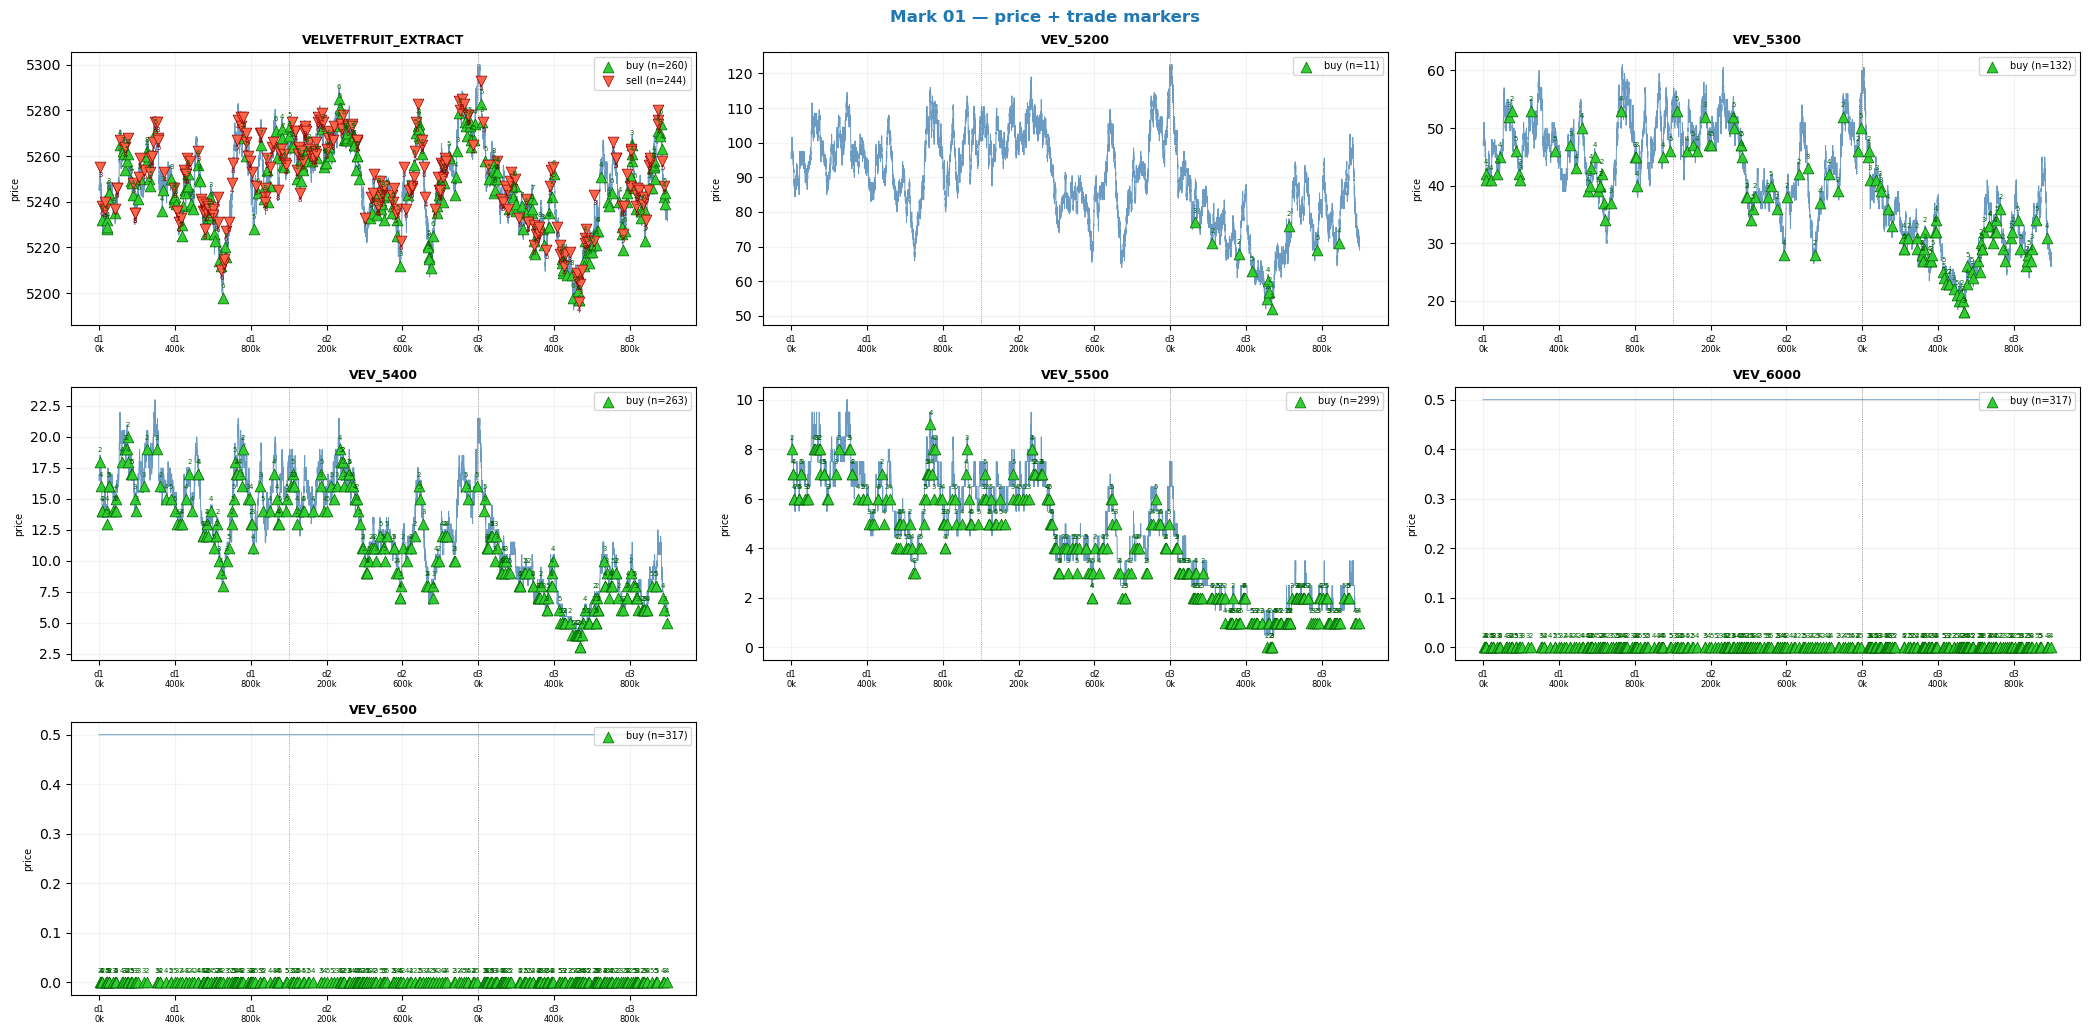

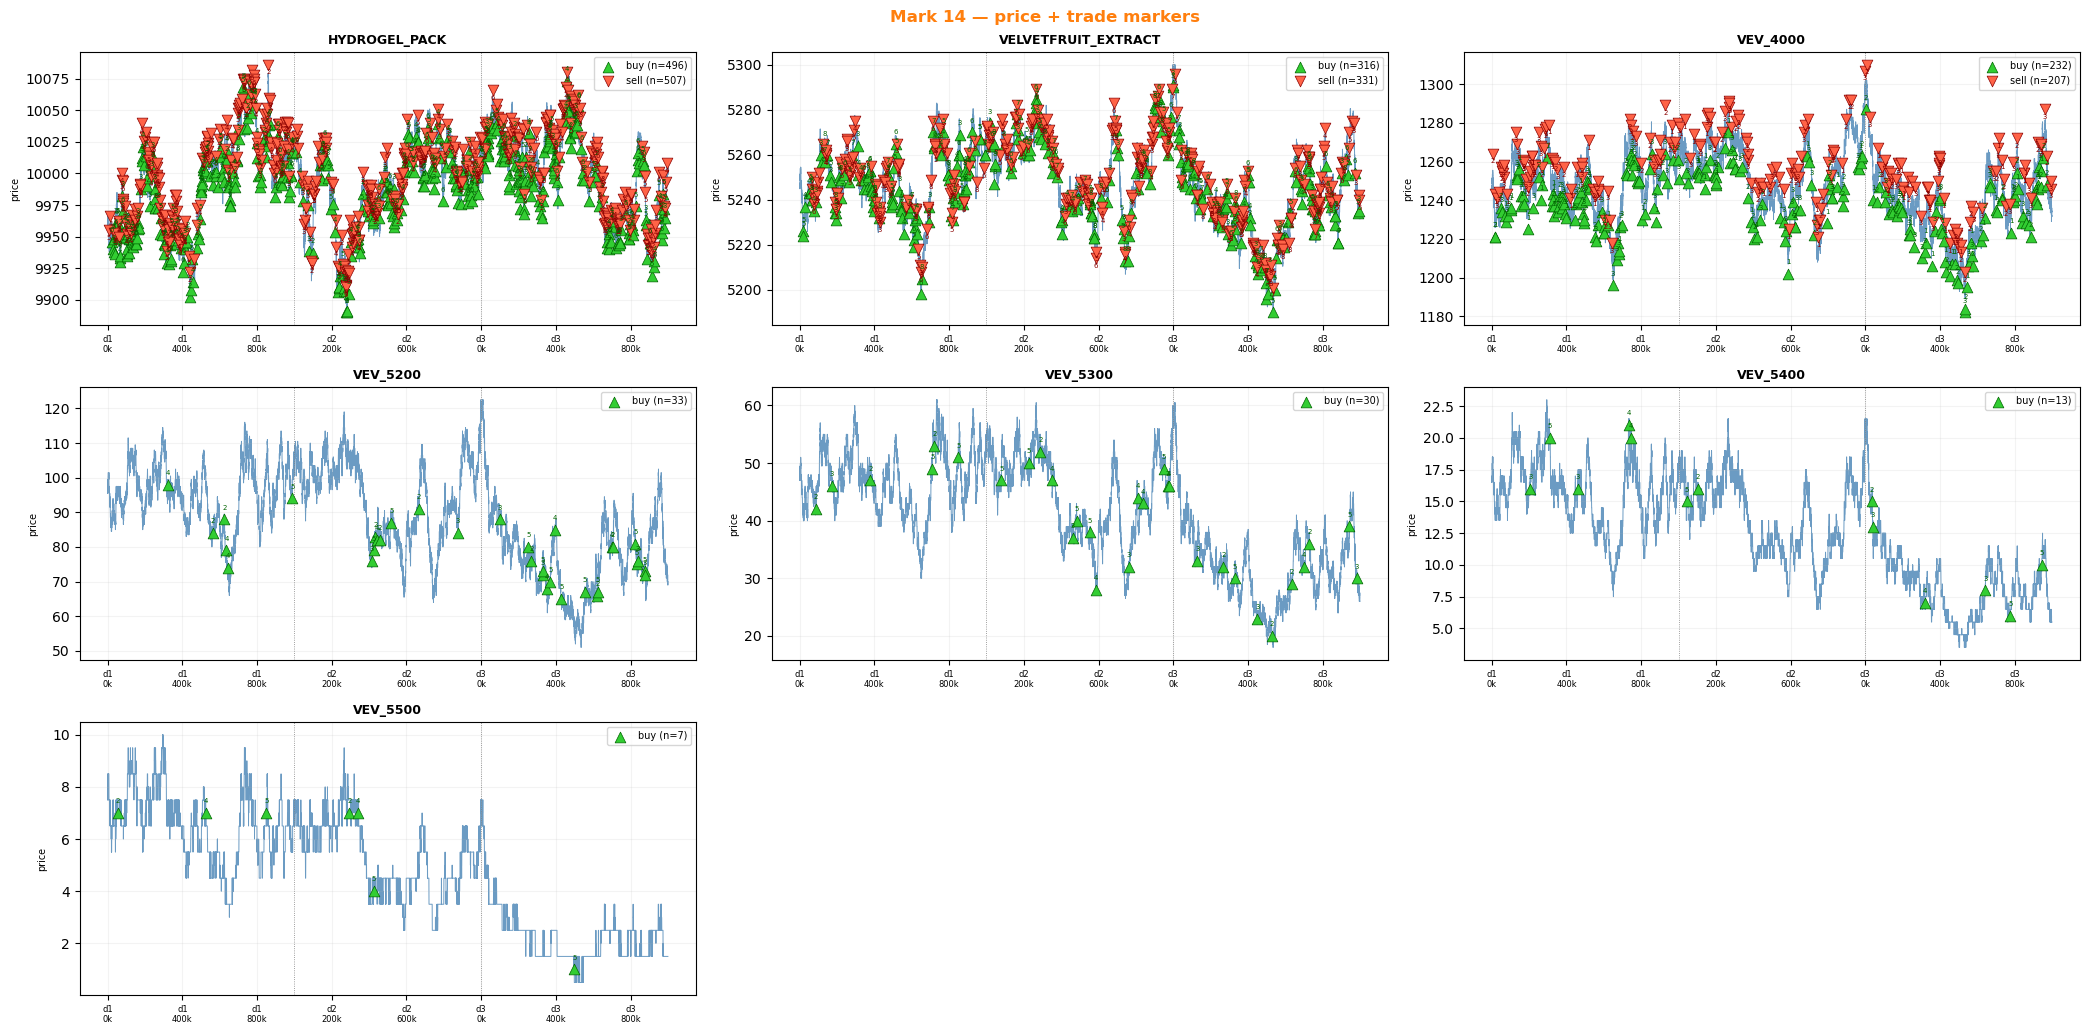

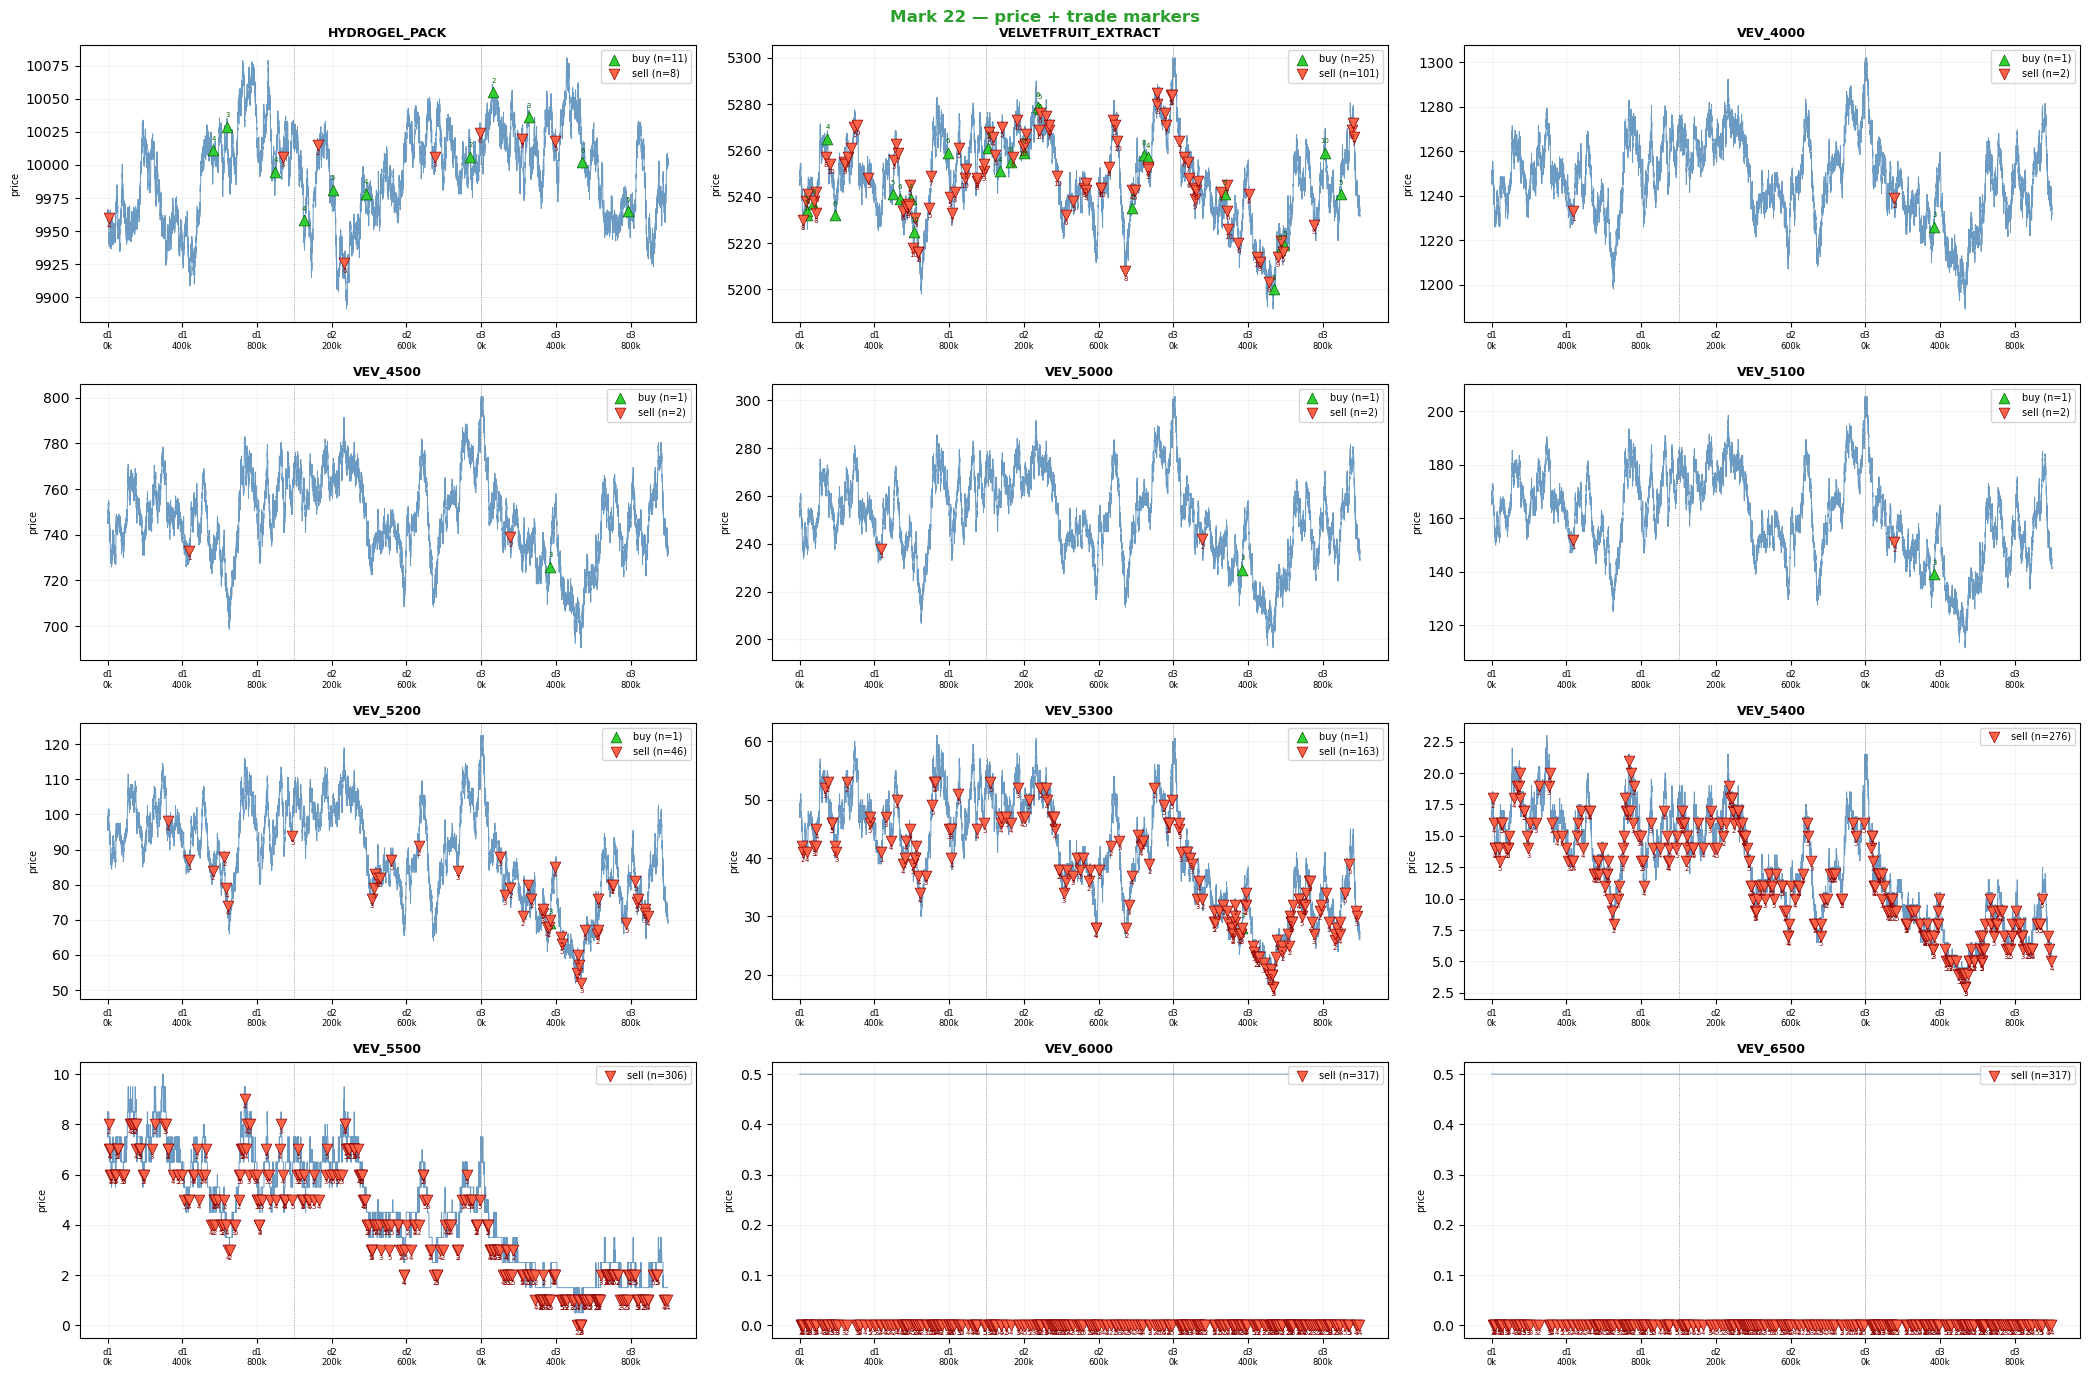

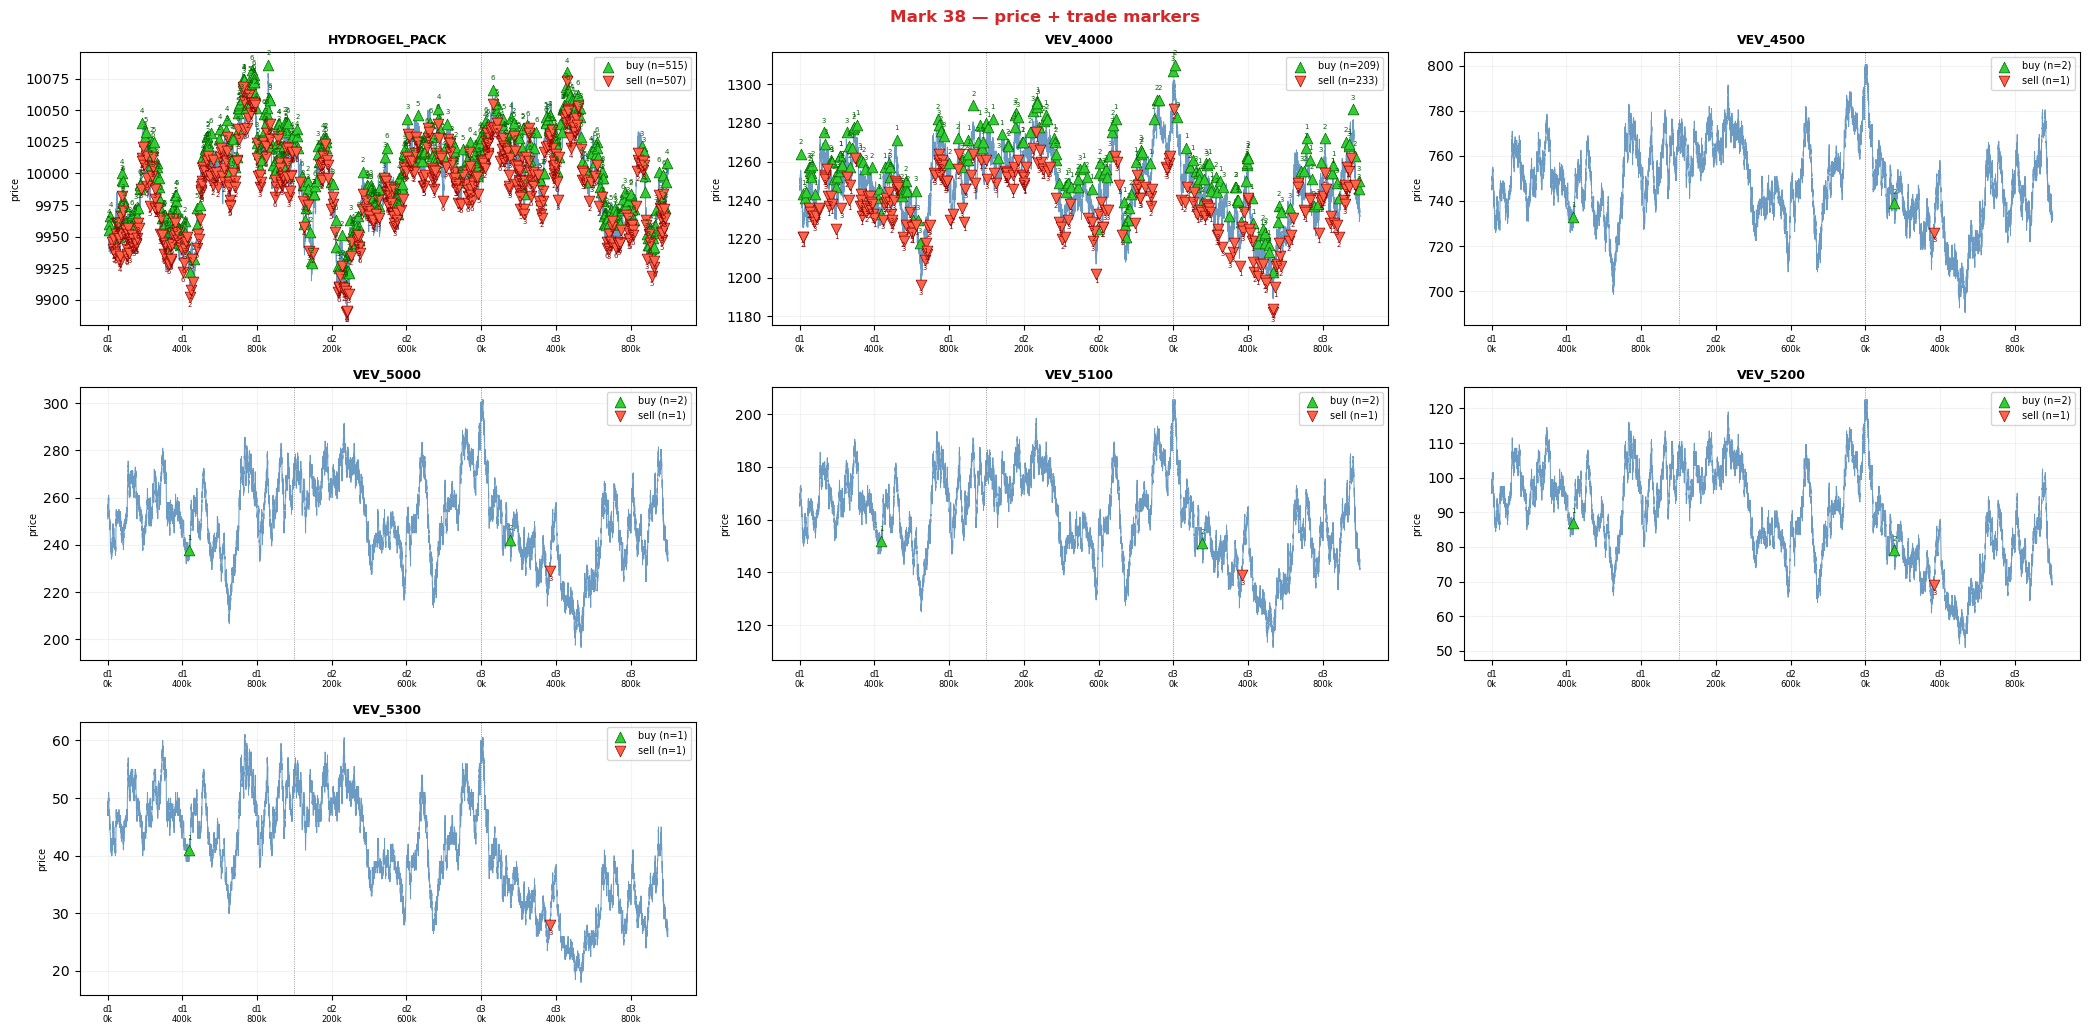

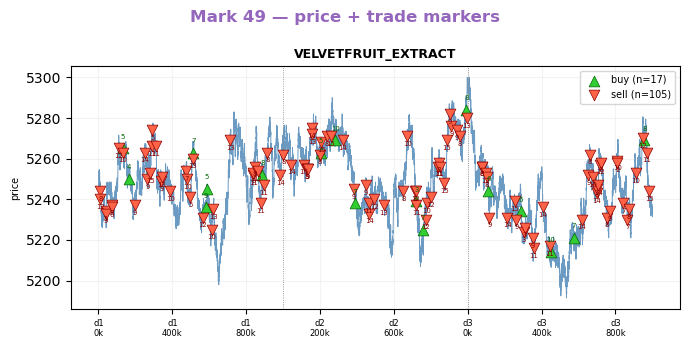

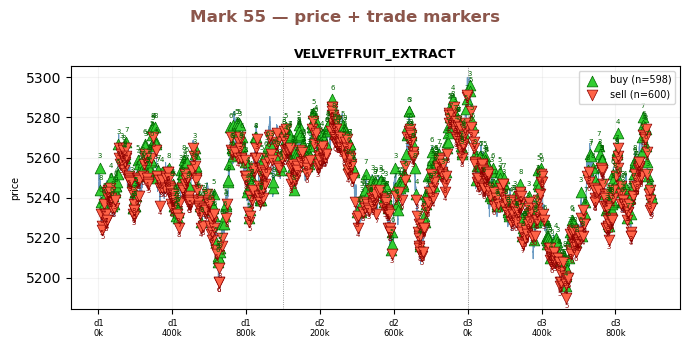

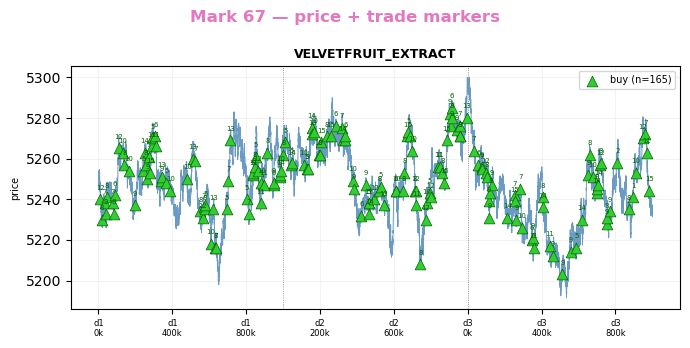

In [4]:
for bot in BOTS:
    bot_trades = trades[(trades['buyer'] == bot) | (trades['seller'] == bot)]
    bot_products = sorted(bot_trades['symbol'].unique(),
                          key=lambda s: PRODUCTS.index(s) if s in PRODUCTS else 99)
    if not bot_products:
        continue

    ncols = min(3, len(bot_products))
    nrows = (len(bot_products) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols,
                              figsize=(7 * ncols, 3.5 * nrows),
                              squeeze=False)
    axes_flat = axes.flatten()

    for idx, prod in enumerate(bot_products):
        ax = axes_flat[idx]

        # mid-price line
        price_sub = prices[prices['product'] == prod]
        ax.plot(price_sub['abs_ts'], price_sub['mid_price'],
                color='steelblue', lw=0.7, alpha=0.8, zorder=1)

        day_vlines(ax)

        # trade markers
        prod_trades = bot_trades[bot_trades['symbol'] == prod]
        buys  = prod_trades[prod_trades['buyer']  == bot]
        sells = prod_trades[prod_trades['seller'] == bot]

        if not buys.empty:
            ax.scatter(buys['abs_ts'], buys['price'],
                       marker='^', color='limegreen', s=60,
                       edgecolors='darkgreen', linewidths=0.5,
                       zorder=3, label=f'buy (n={len(buys)})')
        if not sells.empty:
            ax.scatter(sells['abs_ts'], sells['price'],
                       marker='v', color='tomato', s=60,
                       edgecolors='darkred', linewidths=0.5,
                       zorder=3, label=f'sell (n={len(sells)})')

        # quantity annotations
        for _, row in prod_trades.iterrows():
            is_buy = row['buyer'] == bot
            ax.annotate(str(int(row['quantity'])),
                        xy=(row['abs_ts'], row['price']),
                        xytext=(0, 7 if is_buy else -7),
                        textcoords='offset points',
                        fontsize=5, ha='center',
                        color='darkgreen' if is_buy else 'darkred')

        ax.set_title(prod, fontsize=9, fontweight='bold')
        ax.set_xticks(XT_POS[::2])
        ax.set_xticklabels(XT_LBL[::2], fontsize=6)
        ax.set_ylabel('price', fontsize=7)
        ax.legend(fontsize=7, loc='upper right')
        ax.grid(True, alpha=0.15)

    for idx in range(len(bot_products), len(axes_flat)):
        axes_flat[idx].set_visible(False)

    fig.suptitle(f'{bot} — price + trade markers', fontsize=12, fontweight='bold',
                 color=bot_color[bot])
    plt.tight_layout()
    plt.show()

## Mark 01 — 🟡 for VELVET

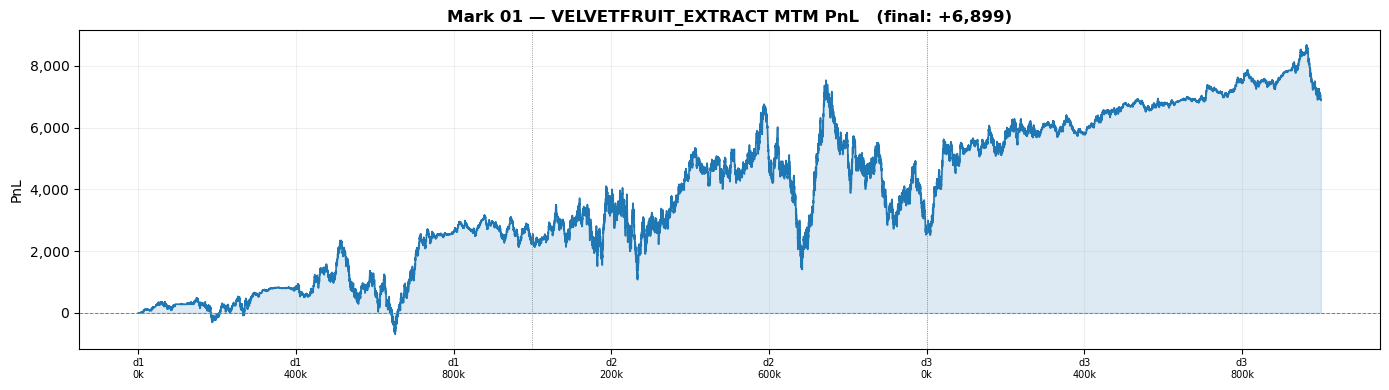

In [5]:
BOT  = 'Mark 01'
PROD = 'VELVETFRUIT_EXTRACT'

bt = trades[(trades['buyer'] == BOT) | (trades['seller'] == BOT)]
bt = bt[bt['symbol'] == PROD].sort_values('abs_ts').copy()
bt['signed_qty'] = bt.apply(lambda r:  r['quantity'] if r['buyer'] == BOT else -r['quantity'], axis=1)
bt['cash_flow']  = bt.apply(lambda r: -r['price'] * r['quantity'] if r['buyer'] == BOT
                              else  r['price'] * r['quantity'], axis=1)
bt['cum_qty']  = bt['signed_qty'].cumsum()
bt['cum_cash'] = bt['cash_flow'].cumsum()

pp = price_snap[price_snap['product'] == PROD].sort_values('abs_ts')
merged = pd.merge_asof(pp, bt[['abs_ts','cum_qty','cum_cash']], on='abs_ts', direction='backward')
merged[['cum_qty','cum_cash']] = merged[['cum_qty','cum_cash']].fillna(0)
merged['pnl'] = merged['cum_cash'] + merged['cum_qty'] * merged['mid_price']

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(merged['abs_ts'], merged['pnl'], color=bot_color[BOT], lw=1.2)
ax.fill_between(merged['abs_ts'], merged['pnl'], alpha=0.15, color=bot_color[BOT])
ax.axhline(0, color='grey', lw=0.7, ls='--')
day_vlines(ax)
ax.set_xticks(XT_POS[::2]); ax.set_xticklabels(XT_LBL[::2], fontsize=7)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_title(f'{BOT} — {PROD} MTM PnL   (final: {merged["pnl"].iloc[-1]:+,.0f})', fontweight='bold')
ax.set_ylabel('PnL'); ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

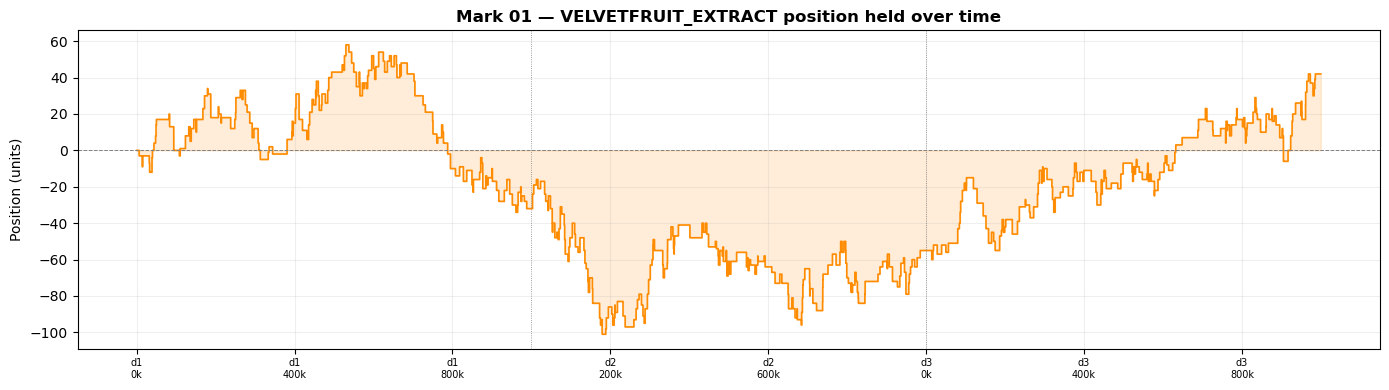

In [6]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.step(merged['abs_ts'], merged['cum_qty'], color='darkorange', lw=1.2, where='post')
ax.fill_between(merged['abs_ts'], merged['cum_qty'], alpha=0.15, color='darkorange', step='post')
ax.axhline(0, color='grey', lw=0.7, ls='--')
day_vlines(ax)
ax.set_xticks(XT_POS[::2]); ax.set_xticklabels(XT_LBL[::2], fontsize=7)
ax.set_title(f'{BOT} — {PROD} position held over time', fontweight='bold')
ax.set_ylabel('Position (units)')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

## Mark 22 — ❌

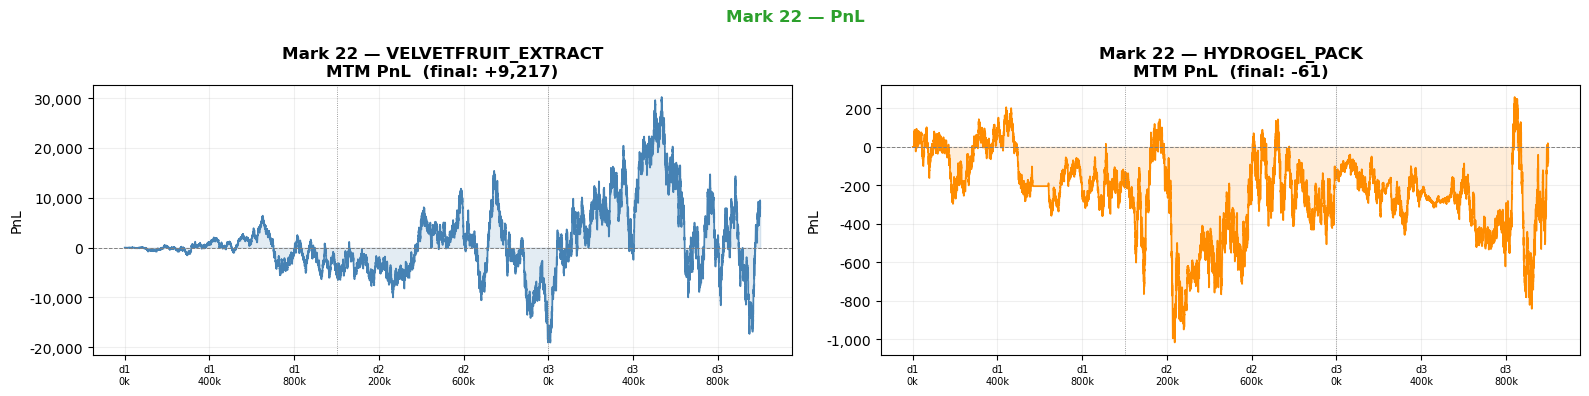

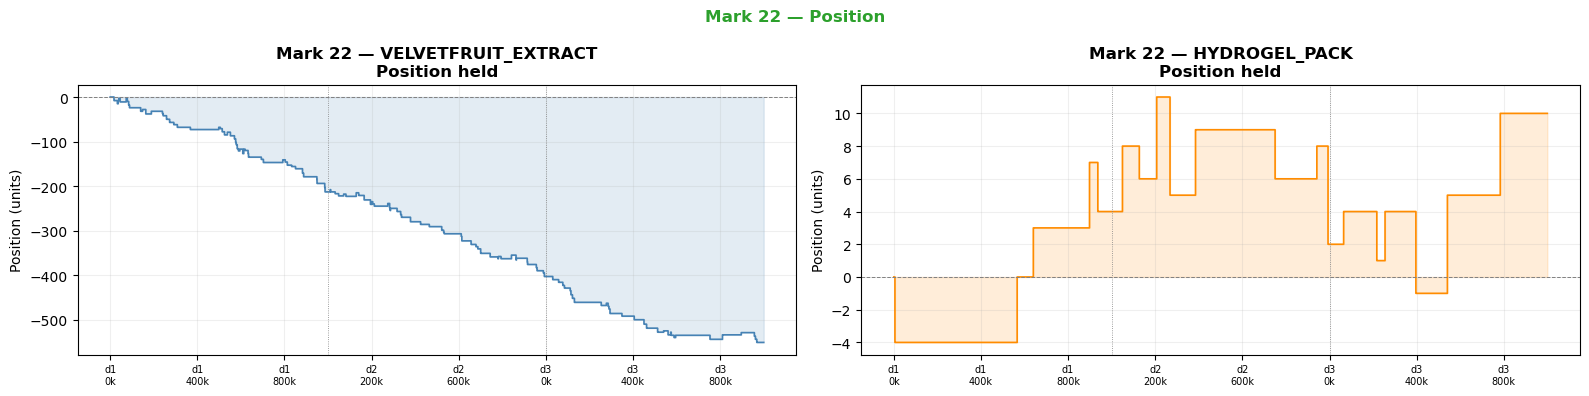

In [7]:
BOT22   = 'Mark 22'
PRODS22 = ['VELVETFRUIT_EXTRACT', 'HYDROGEL_PACK']
COLORS22 = {'VELVETFRUIT_EXTRACT': 'steelblue', 'HYDROGEL_PACK': 'darkorange'}

m22 = {}   # will hold per-product merged dataframes

for prod in PRODS22:
    bt = trades[(trades['buyer'] == BOT22) | (trades['seller'] == BOT22)]
    bt = bt[bt['symbol'] == prod].sort_values('abs_ts').copy()
    bt['signed_qty'] = bt.apply(lambda r:  r['quantity'] if r['buyer'] == BOT22 else -r['quantity'], axis=1)
    bt['cash_flow']  = bt.apply(lambda r: -r['price'] * r['quantity'] if r['buyer'] == BOT22
                                  else  r['price'] * r['quantity'], axis=1)
    bt['cum_qty']  = bt['signed_qty'].cumsum()
    bt['cum_cash'] = bt['cash_flow'].cumsum()

    pp = price_snap[price_snap['product'] == prod].sort_values('abs_ts')
    mg = pd.merge_asof(pp, bt[['abs_ts','cum_qty','cum_cash']], on='abs_ts', direction='backward')
    mg[['cum_qty','cum_cash']] = mg[['cum_qty','cum_cash']].fillna(0)
    mg['pnl'] = mg['cum_cash'] + mg['cum_qty'] * mg['mid_price']
    m22[prod] = mg

# ── PnL — side by side ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, prod in zip(axes, PRODS22):
    mg = m22[prod]
    c  = COLORS22[prod]
    ax.plot(mg['abs_ts'], mg['pnl'], color=c, lw=1.2)
    ax.fill_between(mg['abs_ts'], mg['pnl'], alpha=0.15, color=c)
    ax.axhline(0, color='grey', lw=0.7, ls='--')
    day_vlines(ax)
    ax.set_xticks(XT_POS[::2]); ax.set_xticklabels(XT_LBL[::2], fontsize=7)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.set_title(f'{BOT22} — {prod}\nMTM PnL  (final: {mg["pnl"].iloc[-1]:+,.0f})', fontweight='bold')
    ax.set_ylabel('PnL'); ax.grid(True, alpha=0.2)
plt.suptitle(f'{BOT22} — PnL', fontsize=12, fontweight='bold', color=bot_color[BOT22])
plt.tight_layout()
plt.show()

# ── Position — side by side ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, prod in zip(axes, PRODS22):
    mg = m22[prod]
    c  = COLORS22[prod]
    ax.step(mg['abs_ts'], mg['cum_qty'], color=c, lw=1.2, where='post')
    ax.fill_between(mg['abs_ts'], mg['cum_qty'], alpha=0.15, color=c, step='post')
    ax.axhline(0, color='grey', lw=0.7, ls='--')
    day_vlines(ax)
    ax.set_xticks(XT_POS[::2]); ax.set_xticklabels(XT_LBL[::2], fontsize=7)
    ax.set_title(f'{BOT22} — {prod}\nPosition held', fontweight='bold')
    ax.set_ylabel('Position (units)'); ax.grid(True, alpha=0.2)
plt.suptitle(f'{BOT22} — Position', fontsize=12, fontweight='bold', color=bot_color[BOT22])
plt.tight_layout()
plt.show()

## Mark 14 — HYDROGEL_PACK, VELVETFRUIT_EXTRACT & VEV_4000 PnL and position

In [ ]:
BOT14   = 'Mark 14'
PRODS14 = ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000']
COLORS14 = {'HYDROGEL_PACK': 'darkorange', 'VELVETFRUIT_EXTRACT': 'steelblue', 'VEV_4000': 'mediumseagreen'}

m14 = {}

for prod in PRODS14:
    bt = trades[(trades['buyer'] == BOT14) | (trades['seller'] == BOT14)]
    bt = bt[bt['symbol'] == prod].sort_values('abs_ts').copy()
    bt['signed_qty'] = bt.apply(lambda r:  r['quantity'] if r['buyer'] == BOT14 else -r['quantity'], axis=1)
    bt['cash_flow']  = bt.apply(lambda r: -r['price'] * r['quantity'] if r['buyer'] == BOT14
                                  else  r['price'] * r['quantity'], axis=1)
    bt['cum_qty']  = bt['signed_qty'].cumsum()
    bt['cum_cash'] = bt['cash_flow'].cumsum()

    pp = price_snap[price_snap['product'] == prod].sort_values('abs_ts')
    mg = pd.merge_asof(pp, bt[['abs_ts','cum_qty','cum_cash']], on='abs_ts', direction='backward')
    mg[['cum_qty','cum_cash']] = mg[['cum_qty','cum_cash']].fillna(0)
    mg['pnl'] = mg['cum_cash'] + mg['cum_qty'] * mg['mid_price']
    m14[prod] = mg

# ── PnL ───────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(21, 4))
for ax, prod in zip(axes, PRODS14):
    mg = m14[prod]
    c  = COLORS14[prod]
    ax.plot(mg['abs_ts'], mg['pnl'], color=c, lw=1.2)
    ax.fill_between(mg['abs_ts'], mg['pnl'], alpha=0.15, color=c)
    ax.axhline(0, color='grey', lw=0.7, ls='--')
    day_vlines(ax)
    ax.set_xticks(XT_POS[::2]); ax.set_xticklabels(XT_LBL[::2], fontsize=7)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.set_title(f'{BOT14} — {prod}\nMTM PnL  (final: {mg["pnl"].iloc[-1]:+,.0f})', fontweight='bold')
    ax.set_ylabel('PnL'); ax.grid(True, alpha=0.2)
plt.suptitle(f'{BOT14} — PnL', fontsize=12, fontweight='bold', color=bot_color[BOT14])
plt.tight_layout()
plt.show()

# ── Position ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(21, 4))
for ax, prod in zip(axes, PRODS14):
    mg = m14[prod]
    c  = COLORS14[prod]
    ax.step(mg['abs_ts'], mg['cum_qty'], color=c, lw=1.2, where='post')
    ax.fill_between(mg['abs_ts'], mg['cum_qty'], alpha=0.15, color=c, step='post')
    ax.axhline(0, color='grey', lw=0.7, ls='--')
    day_vlines(ax)
    ax.set_xticks(XT_POS[::2]); ax.set_xticklabels(XT_LBL[::2], fontsize=7)
    ax.set_title(f'{BOT14} — {prod}\nPosition held', fontweight='bold')
    ax.set_ylabel('Position (units)'); ax.grid(True, alpha=0.2)
plt.suptitle(f'{BOT14} — Position', fontsize=12, fontweight='bold', color=bot_color[BOT14])
plt.tight_layout()
plt.show()